In [16]:
import yfinance as yf
import pandas as pd
import numpy as np

In [17]:
sectors = ['XLB', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLU', 'XLV', 'XLY']
industries = ['XBI', 'KRE', 'KBE', 'SMH', 'ITB', 'XHB', 'XME', 'XOP',
              'XRT', 'IYT', 'IYR', 'IBB', 'OIH', 'GDX', 'IGV']
tickers = sectors + industries
benchmark = 'SPY'

start = '2006-07-01'  
print(len(tickers), 'tickers')

24 tickers


In [18]:

raw = yf.download(tickers + [benchmark], start=start, auto_adjust=True, progress=False)
daily = raw['Close']
daily.index = pd.to_datetime(daily.index).tz_localize(None)

print(daily)

Ticker            GDX         IBB         IGV        ITB         IYR  \
Date                                                                   
2006-07-03  34.140362   23.280617    7.382412  33.661034   35.108734   
2006-07-05  33.410534   23.054070    7.252384  33.121029   35.079681   
2006-07-06  33.716042   23.239145    7.178637  33.112450   35.186165   
2006-07-07  33.122005   22.993439    7.130121  32.941006   35.040966   
2006-07-10  32.816502   22.856243    7.036966  32.726727   35.403973   
...               ...         ...         ...        ...         ...   
2026-11-09  91.459999  219.570007  101.459999  99.449997  103.180000   
2026-11-10  86.489998  217.179993  100.330002  96.190002  102.980003   
2026-11-11  85.209999  218.139999  102.230003  95.449997  102.769997   
2026-11-12  81.839996  213.429993  101.449997  93.769997  102.129997   
2026-11-13  81.639999  212.500000  101.190002  94.010002  102.220001   

Ticker            IYT        KBE        KRE         OIH        

In [19]:
check = pd.DataFrame({'first_date': daily.apply(lambda s: s.first_valid_index()),
                      'n_missing': daily.isna().sum()})
check.sort_values('first_date')

,first_date,n_missing
Ticker,,
GDX,2006-07-03,0
XME,2006-07-03,0
XLY,2006-07-03,0
XLV,2006-07-03,0
XLU,2006-07-03,0
XLP,2006-07-03,0
XLK,2006-07-03,0
XLI,2006-07-03,0
XLF,2006-07-03,0


In [20]:
monthly = daily.resample('ME').last()
monthly = monthly.iloc[:-1]   

prices = monthly[tickers]
spy = monthly[benchmark]
print(prices.shape)
prices.tail()

(244, 24)


Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,XBI,...,XHB,XME,XOP,XRT,IYT,IYR,IBB,OIH,GDX,IGV
Date,,,,,,,,,,,,,,,,,,,,,
2026-06-30,50.597153,52.796177,53.420937,184.733505,190.297928,82.527237,45.009052,158.055099,117.022263,158.250000,...,114.917397,106.858177,153.647354,87.554955,86.554749,101.497505,190.179779,372.029999,75.449997,90.599998
2026-07-31,50.198986,59.198124,56.739189,179.357956,175.145615,84.494301,44.026276,161.930267,115.834877,147.009995,...,103.113411,100.582397,176.695450,89.590652,84.698936,104.316597,186.399979,384.809998,74.099998,94.580002
2026-08-31,52.448631,63.582066,57.506474,174.660583,186.282608,84.424759,41.921753,169.889801,116.333778,162.500000,...,102.238297,118.050652,188.209564,85.918411,84.948372,101.874702,209.038757,429.179993,98.510002,109.980003
2026-09-30,48.700001,61.500000,53.400002,166.979996,195.750000,80.599998,39.439999,168.419998,108.839996,157.679993,...,96.029999,103.559998,179.330002,82.150002,78.519997,95.040001,210.529999,378.369995,87.800003,106.480003
2026-10-31,52.740002,70.019997,56.509998,167.399994,179.509995,89.419998,43.430000,184.869995,115.379997,155.979996,...,100.970001,97.820000,203.759995,88.720001,81.610001,99.660004,217.610001,411.570007,77.089996,104.290001


In [21]:
ret = prices.pct_change()
spy_ret = spy.pct_change()


signal = prices.shift(1) / prices.shift(12) - 1

signal.dropna(how='all').head()

Ticker,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY,XBI,...,XHB,XME,XOP,XRT,IYT,IYR,IBB,OIH,GDX,IGV
Date,,,,,,,,,,,,,,,,,,,,,
2007-07-31,0.340512,0.191190,0.119162,0.245216,0.303898,0.124467,0.204470,0.125130,0.229500,0.133897,...,-0.018387,0.371669,0.153678,0.219367,0.170649,0.090614,0.093978,0.209128,-0.019604,0.263508
2007-08-31,0.266642,0.255135,0.005843,0.242986,0.215986,0.051791,0.125459,0.041868,0.134175,0.084758,...,-0.150108,0.344377,0.139485,0.091697,0.178196,-0.036965,0.035753,0.328779,-0.013154,0.142918
2007-09-30,0.258140,0.318474,-0.008097,0.197578,0.191257,0.077148,0.160102,0.049616,0.072876,0.225044,...,-0.235817,0.406562,0.215851,0.006019,0.099898,-0.009926,0.072643,0.387588,0.059170,0.092403
2007-10-31,0.282455,0.358099,-0.007113,0.219923,0.189238,0.107007,0.144022,0.078787,-0.001152,0.147957,...,-0.370512,0.357055,0.251943,-0.056474,0.031844,-0.031856,0.044420,0.444260,0.198151,0.130991
2007-11-30,0.280032,0.282588,-0.031019,0.175382,0.217685,0.133676,0.188645,0.100250,-0.018431,0.202893,...,-0.395450,0.323223,0.287138,-0.052450,0.044437,-0.067640,0.082769,0.311938,0.208839,0.185505


In [22]:

n_valid = signal.notna().sum(axis=1)
n_leg = n_valid // 3                                   

rank = signal.rank(axis=1, ascending=False)          
long_mask = rank.le(n_leg, axis=0)
short_mask = rank.gt(n_valid - n_leg, axis=0)

weights = (long_mask.astype(float).div(n_leg, axis=0)
           - short_mask.astype(float).div(n_leg, axis=0)).fillna(0.0)

print(weights.sum(axis=1).loc[weights.abs().sum(axis=1) > 0].describe())   
print(weights.abs().sum(axis=1).loc[weights.abs().sum(axis=1) > 0].describe())

count    232.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
dtype: float64
count    232.0
mean       2.0
std        0.0
min        2.0
25%        2.0
50%        2.0
75%        2.0
max        2.0
dtype: float64


In [23]:
COST = 0.0005   


held = weights.shift(1).fillna(0.0)
gross = (held * ret).sum(axis=1)


turnover = weights.diff().fillna(weights).abs().sum(axis=1)
cost = turnover.shift(1).fillna(0.0) * COST
net = gross - cost


long_leg = (held.clip(lower=0) * ret).sum(axis=1)
short_leg = (held.clip(upper=0) * ret).sum(axis=1)


first = held.abs().sum(axis=1).gt(0).idxmax()
res = pd.DataFrame({'gross': gross, 'cost': cost, 'net': net,
                    'long_leg': long_leg, 'short_leg': short_leg,
                    'spy': spy_ret}).loc[first:]
res.head()

,gross,cost,net,long_leg,short_leg,spy
Date,,,,,,
2007-08-31,0.007524,0.001000,0.006524,0.003933,0.003591,0.012833
2007-09-30,0.054699,0.000250,0.054449,0.058725,-0.004027,0.038715
2007-10-31,0.040283,0.000500,0.039783,0.042242,-0.001959,0.013567
2007-11-30,0.040862,0.000250,0.040612,-0.050545,0.091407,-0.038733
2007-12-31,0.071306,0.000125,0.071181,0.034960,0.036346,-0.011261


In [24]:
d = '2009-02-28'
print('LONG: ', list(weights.columns[weights.loc[d] > 0]))
print('SHORT:', list(weights.columns[weights.loc[d] < 0]))

LONG:  ['XLK', 'XLP', 'XLU', 'XLV', 'XBI', 'IYT', 'IBB', 'IGV']
SHORT: ['XLB', 'XLF', 'KBE', 'ITB', 'XHB', 'XME', 'IYR', 'OIH']


In [25]:
def stats(r):
    r = r.dropna()
    wealth = (1 + r).cumprod()
    ann_ret = wealth.iloc[-1] ** (12 / len(r)) - 1
    ann_vol = r.std() * np.sqrt(12)
    sharpe = r.mean() / r.std() * np.sqrt(12)         
    max_dd = (wealth / wealth.cummax() - 1).min()
    return pd.Series({'Annualised return': ann_ret, 'Annualised volatility': ann_vol,
                      'Sharpe ratio': sharpe, 'Max drawdown': max_dd,
                      'Worst month': r.min(), 'Best month': r.max()})

perf = pd.DataFrame({'L/S gross': stats(res['gross']),
                     'L/S net': stats(res['net']),
                     'SPY (buy & hold)': stats(res['spy'])})
perf

,L/S gross,L/S net,SPY (buy & hold)
Annualised return,-0.008746,-0.013120,0.109357
Annualised volatility,0.180230,0.180228,0.154907
Sharpe ratio,0.042228,0.017729,0.750746
Max drawdown,-0.604190,-0.611681,-0.507848
Worst month,-0.228788,-0.229038,-0.165187
Best month,0.176554,0.176304,0.126983


In [26]:
w = weights.loc[first:]
n_trades = int((w.diff().fillna(w).abs() > 1e-12).sum().sum())   
total_cost = res['cost'].sum()
avg_turnover = turnover.loc[first:].mean()

turn = pd.Series({'Number of trades': n_trades,
                  'Average monthly turnover (of gross 2)': avg_turnover,
                  'Total cost paid (sum of monthly cost)': total_cost,
                  'Average annual cost drag': res['cost'].mean() * 12})
turn

Number of trades                         1306.000000
Average monthly turnover (of gross 2)       0.727273
Total cost paid (sum of monthly cost)       0.085000
Average annual cost drag                    0.004416
dtype: float64

In [27]:

dollar_net = weights.loc[first:].sum(axis=1).mean()


beta = res['net'].cov(res['spy']) / res['spy'].var()
corr = res['net'].corr(res['spy'])


rolling_beta = res['net'].rolling(36).cov(res['spy']) / res['spy'].rolling(36).var()

expo = pd.Series({'Average net dollar exposure': dollar_net,
                  'Full-sample beta to SPY': beta,
                  'Correlation with SPY': corr,
                  'Rolling 36m beta: min': rolling_beta.min(),
                  'Rolling 36m beta: max': rolling_beta.max()})
expo

Average net dollar exposure    0.000000
Full-sample beta to SPY       -0.171387
Correlation with SPY          -0.147308
Rolling 36m beta: min         -0.892166
Rolling 36m beta: max          0.309956
dtype: float64

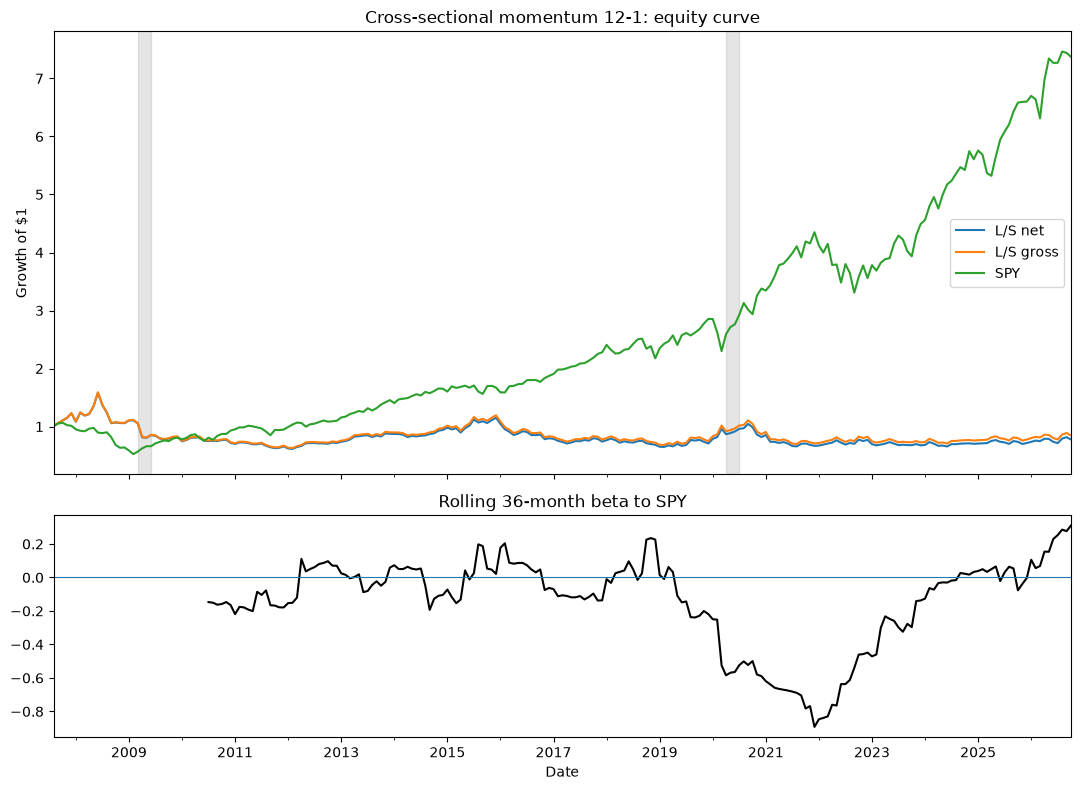

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                       gridspec_kw={'height_ratios': [2, 1]})

(1 + res[['net', 'gross', 'spy']]).cumprod().plot(ax=ax[0])
ax[0].set_title('Cross-sectional momentum 12-1: equity curve')
ax[0].legend(['L/S net', 'L/S gross', 'SPY'])
ax[0].set_ylabel('Growth of $1')
for s, e in [('2009-03', '2009-06'), ('2020-04', '2020-07')]:
    ax[0].axvspan(pd.Timestamp(s), pd.Timestamp(e), color='grey', alpha=0.2)

rolling_beta.plot(ax=ax[1], color='black')
ax[1].axhline(0, lw=0.8)
ax[1].set_title('Rolling 36-month beta to SPY')

plt.tight_layout()
plt.savefig('task2_equity_curve.png', dpi=150)
plt.show()

In [29]:
windows = {'2009 rebound': ('2008-07', '2010-06'),
           '2020 rebound': ('2019-07', '2021-06')}

stretch = {}
for name, (s, e) in windows.items():
    r = res.loc[s:e]
    wealth = (1 + r['net']).cumprod()
    worst = r['net'].idxmin()
    stretch[name] = {'Worst month': worst.strftime('%Y-%m'),
                     'Worst month net return': r['net'].min(),
                     '  long leg that month': r.loc[worst, 'long_leg'],
                     '  short leg that month': r.loc[worst, 'short_leg'],
                     '  SPY that month': r.loc[worst, 'spy'],
                     'Max drawdown in window': (wealth / wealth.cummax() - 1).min()}
stretch = pd.DataFrame(stretch)
stretch

,2009 rebound,2020 rebound
Worst month,2009-04,2021-02
Worst month net return,-0.229038,-0.136935
long leg that month,0.010279,0.005268
short leg that month,-0.239067,-0.141953
SPY that month,0.099346,0.027806
Max drawdown in window,-0.456237,-0.323336


In [30]:

legs_2009 = res.loc['2009-03':'2009-08', ['long_leg', 'short_leg', 'net', 'spy']]
legs_2020 = res.loc['2020-04':'2020-09', ['long_leg', 'short_leg', 'net', 'spy']]


for d in ['2009-02-28', '2020-03-31']:
    print(d, 'LONG: ', list(weights.columns[weights.loc[d] > 0]))
    print(d, 'SHORT:', list(weights.columns[weights.loc[d] < 0]))

display(legs_2009, legs_2020)

2009-02-28 LONG:  ['XLK', 'XLP', 'XLU', 'XLV', 'XBI', 'IYT', 'IBB', 'IGV']
2009-02-28 SHORT: ['XLB', 'XLF', 'KBE', 'ITB', 'XHB', 'XME', 'IYR', 'OIH']
2020-03-31 LONG:  ['XLK', 'XLP', 'XLU', 'SMH', 'ITB', 'XHB', 'GDX', 'IGV']
2020-03-31 SHORT: ['XLE', 'KRE', 'KBE', 'XME', 'XOP', 'XRT', 'IYT', 'OIH']


,long_leg,short_leg,net,spy
Date,,,,
2009-03-31,0.068477,-0.115347,-0.047120,0.083311
2009-04-30,0.010279,-0.239067,-0.229038,0.099346
2009-05-31,0.071762,-0.080428,-0.008917,0.058453
2009-06-30,0.009769,0.047919,0.057313,-0.000655
2009-07-31,0.075514,-0.089461,-0.014197,0.074606
2009-08-31,0.017005,-0.073083,-0.056578,0.036940


,long_leg,short_leg,net,spy
Date,,,,
2020-04-30,0.175011,-0.271417,-0.096531,0.126983
2020-05-31,0.059794,-0.039413,0.020132,0.047646
2020-06-30,0.044439,-0.011532,0.032657,0.017734
2020-07-31,0.067291,-0.016798,0.050367,0.058892
2020-08-31,0.046238,-0.036676,0.009562,0.069797
2020-09-30,-0.022088,0.099572,0.077233,-0.037444


In [32]:
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.drawing.image import Image

header_fill = PatternFill('solid', start_color='F4B183')
first_col_fill = PatternFill('solid', start_color='FCE4D6')
side = Side(style='thin', color='000000')
border = Border(left=side, right=side, top=side, bottom=side)

def write_block(xw, ws, df, startrow, title, fmt):
    df.to_excel(xw, sheet_name='Report', startrow=startrow + 1)
    ws.cell(startrow + 1, 1, title).font = Font(name='Arial', size=12, bold=True)
    head = startrow + 2
    for row in ws.iter_rows(min_row=head, max_row=head + len(df), max_col=df.shape[1] + 1):
        for c in row:
            c.border = border
            c.font = Font(name='Arial', size=10)
            if c.row == head:
                c.fill, c.font = header_fill, Font(name='Arial', size=10, bold=True)
                c.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
            elif c.column == 1:
                c.fill = first_col_fill
            else:
                c.alignment = Alignment(horizontal='right')
                if isinstance(c.value, (int, float)):
                    c.number_format = fmt(str(ws.cell(c.row, 1).value), ws.cell(head, c.column).value)
    return head + len(df) + 2          # one empty row between blocks

pct_words = ('return', 'volatility', 'drawdown', 'month', 'cost', 'leg', 'SPY')
by_label = lambda label, col: '0.00%' if any(w in label for w in pct_words) else '0.00'
all_pct = lambda label, col: '0.00%'

legs = pd.concat([legs_2009, legs_2020])
legs.index = legs.index.strftime('%Y-%m')
legs.index.name = 'Month'

with pd.ExcelWriter('task2_results.xlsx', engine='openpyxl') as xw:
    pd.DataFrame().to_excel(xw, sheet_name='Report')
    ws = xw.sheets['Report']
    ws['A1'] = 'Cross-sectional momentum 12-1: 24 sector/industry ETFs, top vs bottom third, 5 bp per side'
    ws['A1'].font = Font(name='Arial', size=14, bold=True)

    r = 2
    r = write_block(xw, ws, perf, r, 'Performance', by_label)
    r = write_block(xw, ws, turn.to_frame('Value'), r, 'Turnover and transaction costs',
                    lambda l, c: '0' if 'trades' in l else ('0.00%' if 'cost' in l else '0.00'))
    r = write_block(xw, ws, expo.to_frame('Value'), r, 'Net market exposure', by_label)
    r = write_block(xw, ws, stretch, r, 'Stretch: momentum crash in 2009 and 2020 rebounds', by_label)
    r = write_block(xw, ws, legs, r, 'Leg decomposition in rebound months', all_pct)

    ws.column_dimensions['A'].width = 40
    for col in 'BCDE':
        ws.column_dimensions[col].width = 18
    ws.add_image(Image('task2_equity_curve.png'), 'G3')